# Descarga de datos

Compre el 20/7/2026 chequear en una semana

In [2]:
# 1. Instalamos yfinance (en Colab a veces ya viene, pero por las dudas la actualizamos)
!pip install yfinance --upgrade -q






   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.2/144.2 kB 3.7 MB/s eta 0:00:00


In [3]:
# 2. Importamos las librerías que vamos a necesitar
import yfinance as yf
import pandas as pd


In [4]:
# 3. Descargamos los datos históricos de ABEV
import datetime
ticker = "GGB"
data = yf.download(ticker, start="2020-01-01", end=datetime.date.today() + datetime.timedelta(days=1))

[*********************100%***********************]  1 of 1 completed


In [5]:
# 4. Vemos las primeras filas para confirmar que se descargó bien
data.head()

Price,Close,High,Low,Open,Volume
Ticker,GGB,GGB,GGB,GGB,GGB
Date,,,,,
2020-01-02,2.704408,2.720347,2.667216,2.699095,12175002
2020-01-03,2.635336,2.683155,2.598144,2.651276,20898990
2020-01-06,2.635336,2.651276,2.576891,2.603457,17490816
2020-01-07,2.672529,2.693782,2.598144,2.614084,13978818
2020-01-08,2.688468,2.725661,2.661902,2.661902,7888482


# Exploracion datos

In [6]:
# 1. Forma del DataFrame: cuántas filas (días) y columnas tenemos
print("Filas y columnas:", data.shape)






Filas y columnas: (1645, 5)


In [7]:
# 3. Estadísticas descriptivas: mínimo, máximo, promedio, etc.
data.describe()


Price,Close,High,Low,Open,Volume
Ticker,GGB,GGB,GGB,GGB,GGB
count,1645.000000,1645.000000,1645.000000,1645.000000,1.645000e+03
mean,3.118171,3.166497,3.072536,3.118754,1.279773e+07
std,0.745191,0.748931,0.741843,0.744457,7.839128e+06
min,0.915580,0.952842,0.878319,0.920904,9.170280e+05
25%,2.763398,2.812434,2.723913,2.769034,7.197800e+06
50%,3.160417,3.202654,3.109586,3.158672,1.081382e+07
75%,3.577306,3.634957,3.523234,3.577382,1.624800e+07
max,4.892318,4.941936,4.773236,4.892319,6.573550e+07


In [8]:
# 4. Chequeamos específicamente si hay valores nulos/faltantes
print("\nValores faltantes por columna:")
print(data.isnull().sum())



Valores faltantes por columna:
Price   Ticker
Close   GGB       0
High    GGB       0
Low     GGB       0
Open    GGB       0
Volume  GGB       0
dtype: int64


In [9]:

# 5. Vemos las últimas filas (para confirmar que los datos llegan hasta la fecha reciente)
data.tail()

Price,Close,High,Low,Open,Volume
Ticker,GGB,GGB,GGB,GGB,GGB
Date,,,,,
2026-07-15,4.80,4.83,4.63,4.65,31784400
2026-07-16,4.72,4.81,4.69,4.72,16115000
2026-07-17,4.72,4.77,4.61,4.63,9829900
2026-07-20,4.68,4.76,4.64,4.75,7871200
2026-07-21,4.64,4.70,4.62,4.70,14017100


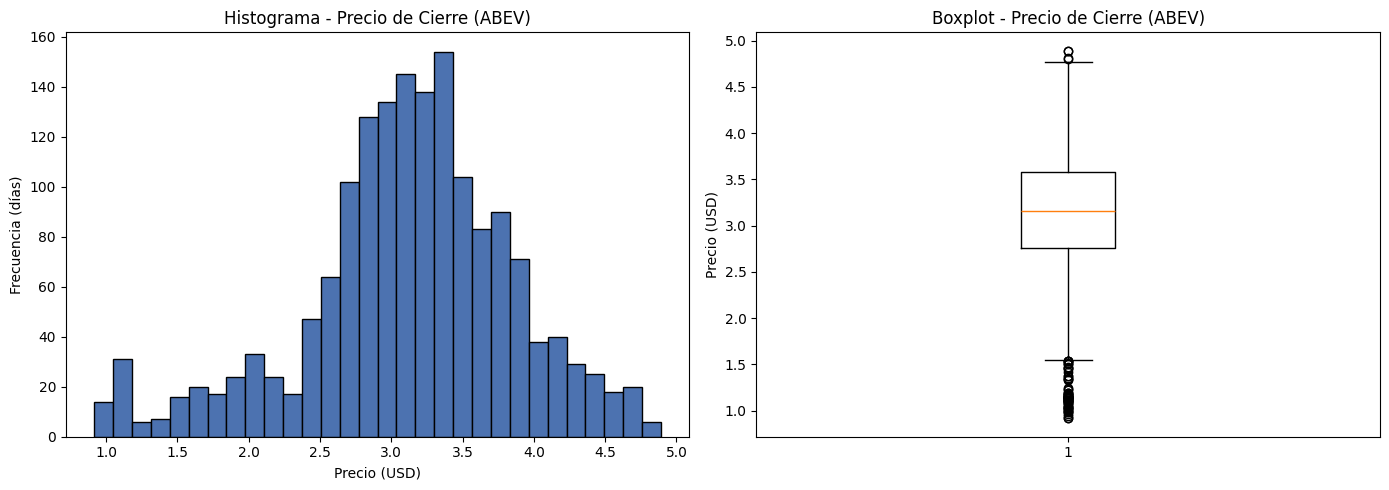

In [10]:
import matplotlib.pyplot as plt

# Creamos una figura con 2 gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Histograma ---
axes[0].hist(data['Close'], bins=30, color='#4C72B0', edgecolor='black')
axes[0].set_title('Histograma - Precio de Cierre (ABEV)')
axes[0].set_xlabel('Precio (USD)')
axes[0].set_ylabel('Frecuencia (días)')

# --- Boxplot ---
axes[1].boxplot(data['Close'], vert=True)
axes[1].set_title('Boxplot - Precio de Cierre (ABEV)')
axes[1].set_ylabel('Precio (USD)')

plt.tight_layout()
plt.show()

# Graficos de tendencia 2020-2026

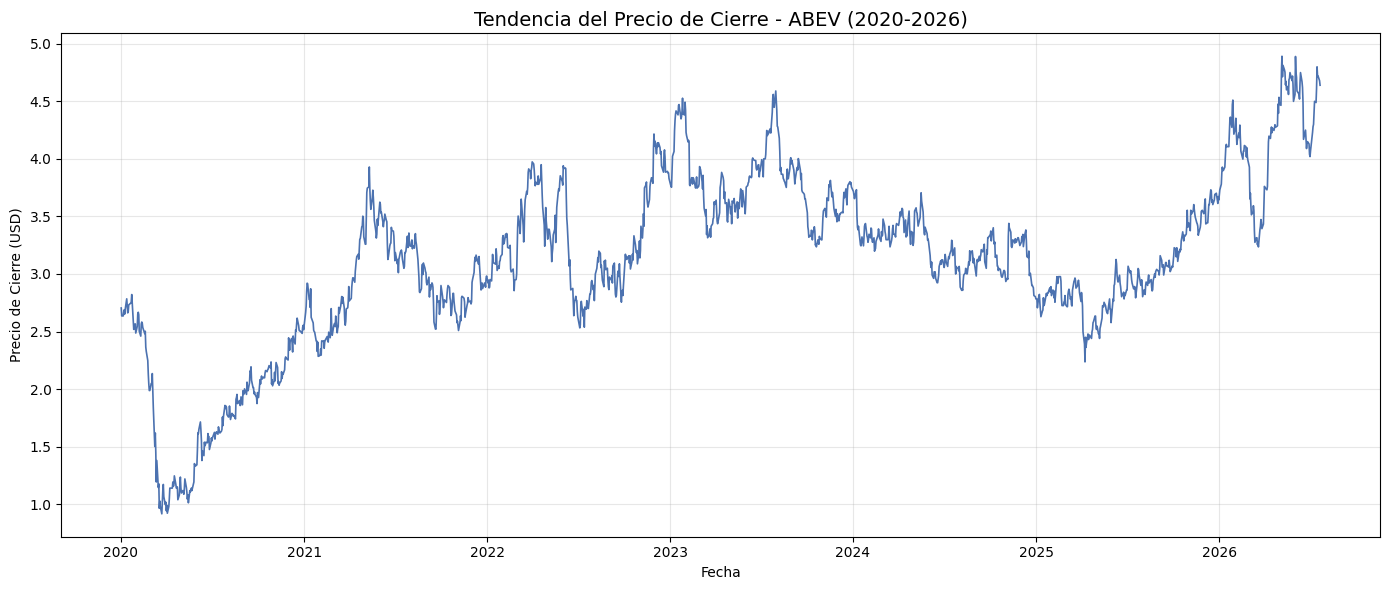

In [11]:
# Gráfico de tendencia - Precio de cierre en el tiempo
plt.figure(figsize=(14, 6))
plt.plot(data.index, data['Close'], color='#4C72B0', linewidth=1.2)

plt.title('Tendencia del Precio de Cierre - ABEV (2020-2026)', fontsize=14)
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

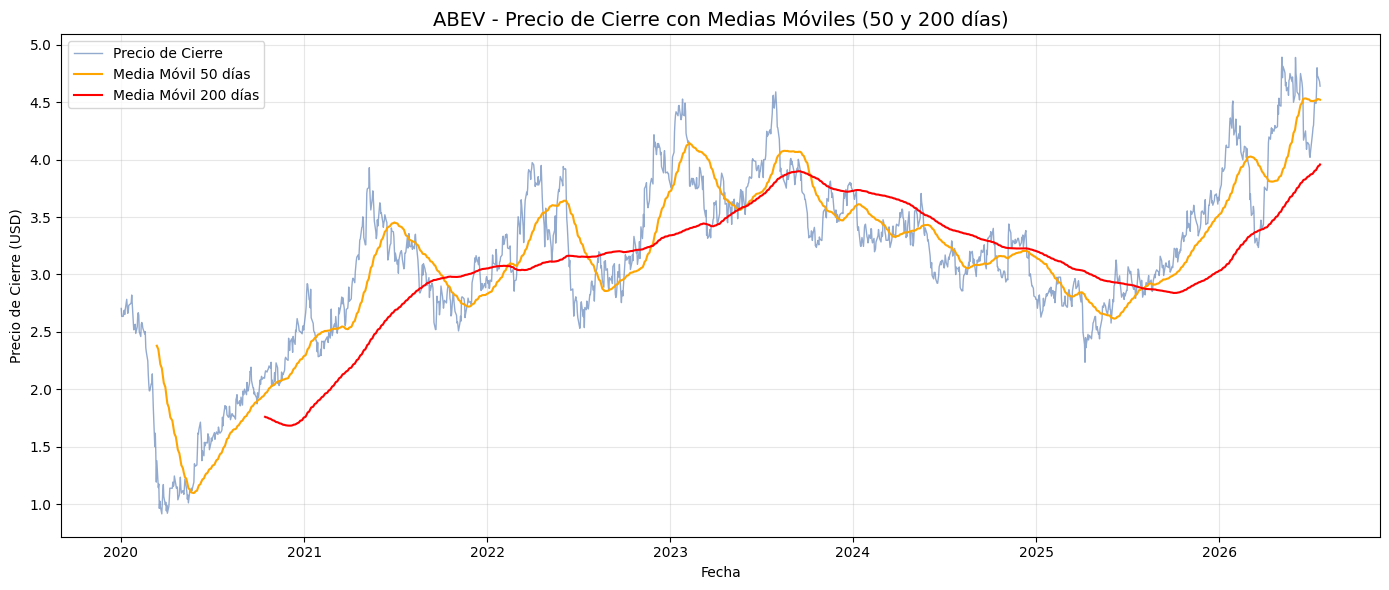

In [12]:
# Calculamos las medias móviles
data['MA50'] = data['Close'].rolling(window=50).mean()
data['MA200'] = data['Close'].rolling(window=200).mean()

# Graficamos precio + medias móviles
plt.figure(figsize=(14, 6))
plt.plot(data.index, data['Close'], color='#4C72B0', linewidth=1, alpha=0.6, label='Precio de Cierre')
plt.plot(data.index, data['MA50'], color='orange', linewidth=1.5, label='Media Móvil 50 días')
plt.plot(data.index, data['MA200'], color='red', linewidth=1.5, label='Media Móvil 200 días')

plt.title('ABEV - Precio de Cierre con Medias Móviles (50 y 200 días)', fontsize=14)
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Graficos de tendencia 2024-2026

In [13]:
# Filtramos los datos desde 2024 en adelante
data_reciente = data[data.index >= '2024-01-01']

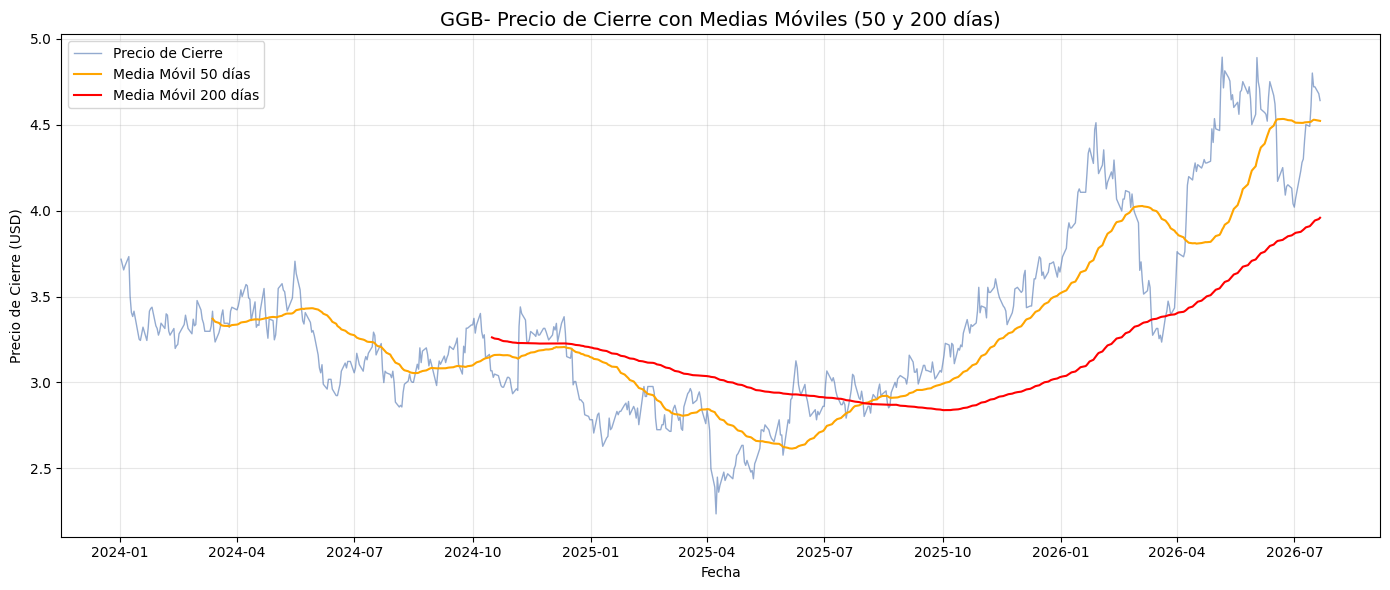

In [14]:
# Calculamos las medias móviles
data_reciente_copy = data_reciente.copy()

# Explicitly get the 'Close' prices as a Series, handling the MultiIndex
# The 'ticker' variable (ABEV) is defined earlier in the notebook.
close_prices_for_ma = data_reciente_copy[('Close', ticker)]

data_reciente_copy['MA50'] = close_prices_for_ma.rolling(window=50).mean()
data_reciente_copy['MA200'] = close_prices_for_ma.rolling(window=200).mean()

# Graficamos precio + medias móviles
plt.figure(figsize=(14, 6))
# Plot the explicit 'Close' prices
plt.plot(data_reciente_copy.index, close_prices_for_ma, color='#4C72B0', linewidth=1, alpha=0.6, label='Precio de Cierre')
plt.plot(data_reciente_copy.index, data_reciente_copy['MA50'], color='orange', linewidth=1.5, label='Media Móvil 50 días')
plt.plot(data_reciente_copy.index, data_reciente_copy['MA200'], color='red', linewidth=1.5, label='Media Móvil 200 días')

plt.title('GGB- Precio de Cierre con Medias Móviles (50 y 200 días)', fontsize=14)
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Empesamos con arima para 2020-2026 y 2024-2026

In [15]:
!pip install statsmodels -q

from statsmodels.tsa.stattools import adfuller

# Test ADF sobre el precio de cierre original
resultado = adfuller(data['Close'].dropna())

print("Estadístico ADF:", resultado[0])
print("p-value:", resultado[1])
print("Valores críticos:", resultado[4])

if resultado[1] < 0.05:
    print("\n✅ La serie es estacionaria (rechazamos H0)")
else:
    print("\n❌ La serie NO es estacionaria (no rechazamos H0) -> hay que diferenciarla")

Estadístico ADF: -1.7839081802485728
p-value: 0.38847959211505323
Valores críticos: {'1%': np.float64(-3.4343339050195465), '5%': np.float64(-2.8632996655963554), '10%': np.float64(-2.567706805740553)}

❌ La serie NO es estacionaria (no rechazamos H0) -> hay que diferenciarla


 # Arima 2024-2026

In [16]:
# Filtramos los datos desde 2024 en adelante
data_reciente = data[data.index >= '2024-01-01']

# Test ADF sobre este subconjunto
resultado_reciente = adfuller(data_reciente['Close'].dropna())

print("Estadístico ADF:", resultado_reciente[0])
print("p-value:", resultado_reciente[1])
print("Valores críticos:", resultado_reciente[4])

if resultado_reciente[1] < 0.05:
    print("\n✅ La serie reciente es estacionaria")
else:
    print("\n❌ La serie reciente NO es estacionaria -> hay que diferenciarla")

Estadístico ADF: -1.0159341662037946
p-value: 0.7474084070473578
Valores críticos: {'1%': np.float64(-3.440641231176813), '5%': np.float64(-2.8660808067889976), '10%': np.float64(-2.569188186240308)}

❌ La serie reciente NO es estacionaria -> hay que diferenciarla


In [17]:
# Diferenciamos la serie reciente
data_reciente_diff = data_reciente['Close'].diff().dropna()

# Volvemos a testear ADF sobre la serie diferenciada
resultado_diff = adfuller(data_reciente_diff)

print("Estadístico ADF (diferenciada):", resultado_diff[0])
print("p-value (diferenciada):", resultado_diff[1])

if resultado_diff[1] < 0.05:
    print("\n✅ Ahora sí es estacionaria -> usamos d=1")
else:
    print("\n❌ Todavía no es estacionaria -> probamos con una segunda diferenciación (d=2)")

Estadístico ADF (diferenciada): -18.86342270900893
p-value (diferenciada): 0.0

✅ Ahora sí es estacionaria -> usamos d=1


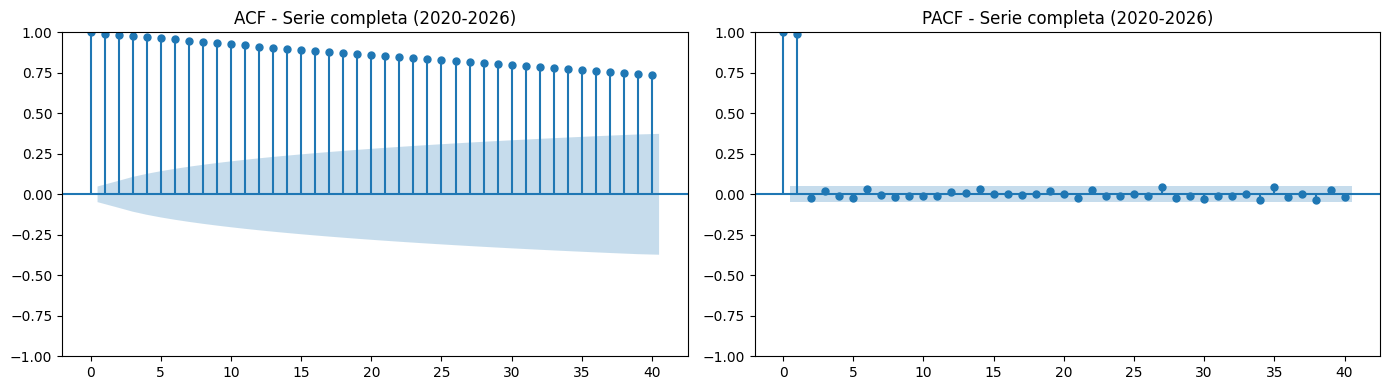

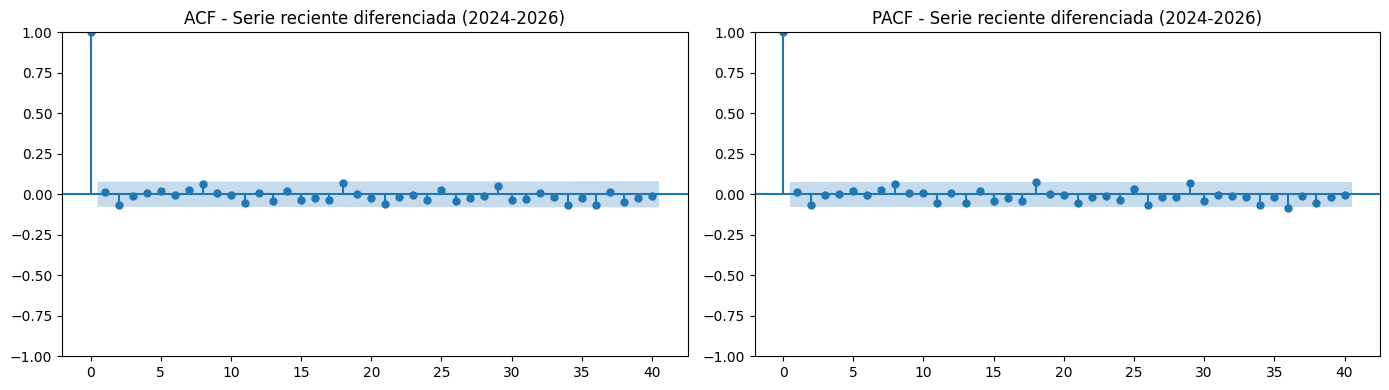

In [18]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# --- CAMINO 1: Serie completa (d=0), usamos el Close original ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(data['Close'].dropna(), lags=40, ax=axes[0])
axes[0].set_title('ACF - Serie completa (2020-2026)')
plot_pacf(data['Close'].dropna(), lags=40, ax=axes[1])
axes[1].set_title('PACF - Serie completa (2020-2026)')
plt.tight_layout()
plt.show()

# --- CAMINO 2: Serie reciente diferenciada (d=1) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(data_reciente_diff, lags=40, ax=axes[0])
axes[0].set_title('ACF - Serie reciente diferenciada (2024-2026)')
plot_pacf(data_reciente_diff, lags=40, ax=axes[1])
axes[1].set_title('PACF - Serie reciente diferenciada (2024-2026)')
plt.tight_layout()
plt.show()

In [19]:
!pip install pmdarima -q
import pmdarima as pm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 12.1 MB/s eta 0:00:00


Camino 2: Serie reciente (2024-2026)

In [20]:
modelo_auto_2 = pm.auto_arima(
    data_reciente['Close'].dropna(),
    seasonal=False,
    trace=True,
    suppress_warnings=True,
    stepwise=True
)

print(modelo_auto_2.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-1470.818, Time=3.33 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-1475.944, Time=0.21 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-1474.062, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-1474.079, Time=0.64 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-1477.712, Time=0.25 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-1473.066, Time=1.67 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 6.280 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  639
Model:               SARIMAX(0, 1, 0)   Log Likelihood                 739.856
Date:                Wed, 22 Jul 2026   AIC                          -1477.712
Time:                        12:21:46   BIC                          -1473.253
Sample:                             0   HQIC                         -1475.981
    

Separar en Train y Test

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Usamos el Camino 2 (datos recientes, 2024-2026)
serie = data_reciente['Close'].dropna()

# Separamos: dejamos los últimos 30 días para test, el resto para entrenar
n_test = 30
train = serie[:-n_test]
test = serie[-n_test:]

print("Días de entrenamiento:", len(train))
print("Días de test:", len(test))

Días de entrenamiento: 609
Días de test: 30


Entrenar el modelo ARIMA(0,1,0)

In [22]:
from statsmodels.tsa.arima.model import ARIMA

modelo = ARIMA(train, order=(0,1,1))
modelo_fit = modelo.fit()

print(modelo_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                    GGB   No. Observations:                  609
Model:                 ARIMA(0, 1, 1)   Log Likelihood                 716.338
Date:                Wed, 22 Jul 2026   AIC                          -1428.675
Time:                        12:21:47   BIC                          -1419.855
Sample:                             0   HQIC                         -1425.244
                                - 609                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.0046      0.036     -0.127      0.899      -0.075       0.066
sigma2         0.0055      0.000     25.024      0.000       0.005       0.006
Ljung-Box (L1) (Q):                   0.00   Jarque-

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


Predecir los 30 días de test

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


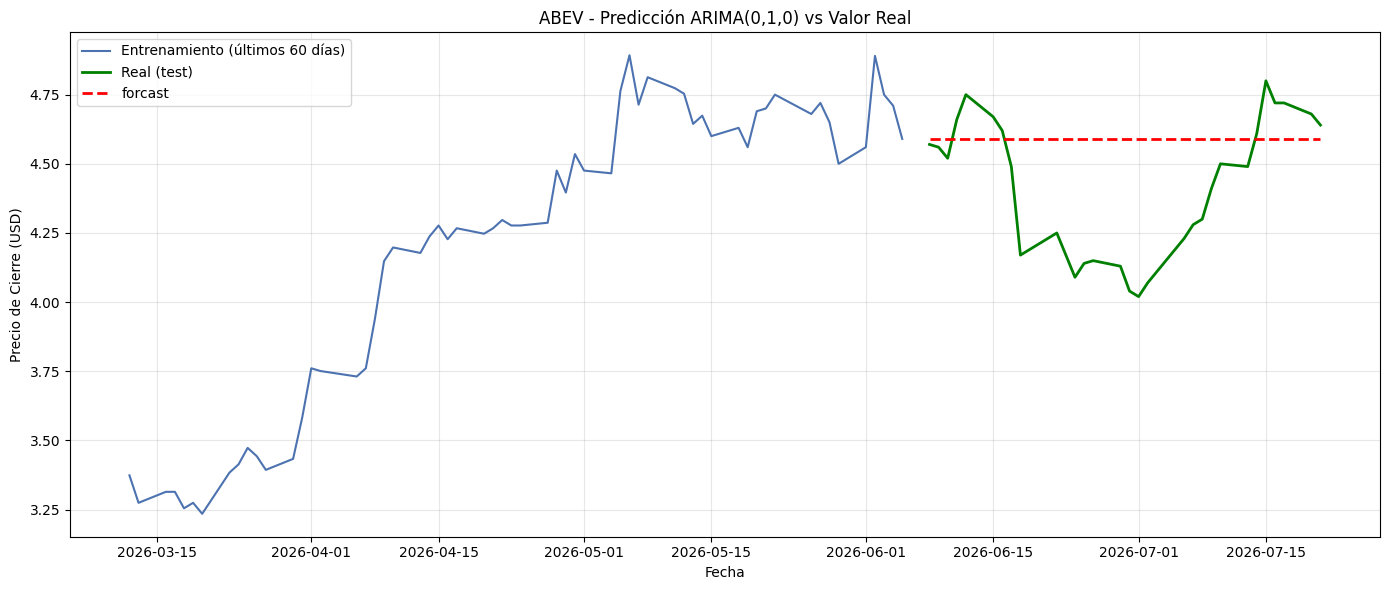

In [23]:
predicciones = modelo_fit.forecast(steps=n_test)

# Graficamos: real vs predicho
plt.figure(figsize=(14,6))
plt.plot(train.index[-60:], train[-60:], label='Entrenamiento (últimos 60 días)', color='#4C72B0')
plt.plot(test.index, test, label='Real (test)', color='green', linewidth=2)
plt.plot(test.index, predicciones, label='forcast', color='red', linestyle='--', linewidth=2)

plt.title('ABEV - Predicción ARIMA(0,1,0) vs Valor Real')
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Medir el error

In [24]:
mae = mean_absolute_error(test, predicciones)
rmse = np.sqrt(mean_squared_error(test, predicciones))
mape = np.mean(np.abs((test - predicciones) / test)) * 100

print(f"MAE  (Error Absoluto Medio): ${mae:.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): ${rmse:.4f}")
# Convertimos a arrays de numpy para evitar el problema de alineación de índices
test_vals = test.values
pred_vals = predicciones.values if hasattr(predicciones, 'values') else np.array(predicciones)

mape = np.mean(np.abs((test_vals - pred_vals) / test_vals)) * 100
print(f"MAPE (corregido): {mape:.2f}%")

MAE  (Error Absoluto Medio): $0.2398
RMSE (Raíz del Error Cuadrático Medio): $0.3018
MAPE (corregido): 5.66%


intervalos de confianza

In [25]:
# Usamos get_forecast() para obtener también los intervalos de confianza
forecast_obj = modelo_fit.get_forecast(steps=n_test)

predicciones = forecast_obj.predicted_mean
intervalo = forecast_obj.conf_int(alpha=0.05)  # 95% de confianza

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [26]:
# El intervalo viene como DataFrame con 2 columnas: límite inferior y superior
limite_inferior = intervalo.iloc[:, 0]
limite_superior = intervalo.iloc[:, 1]


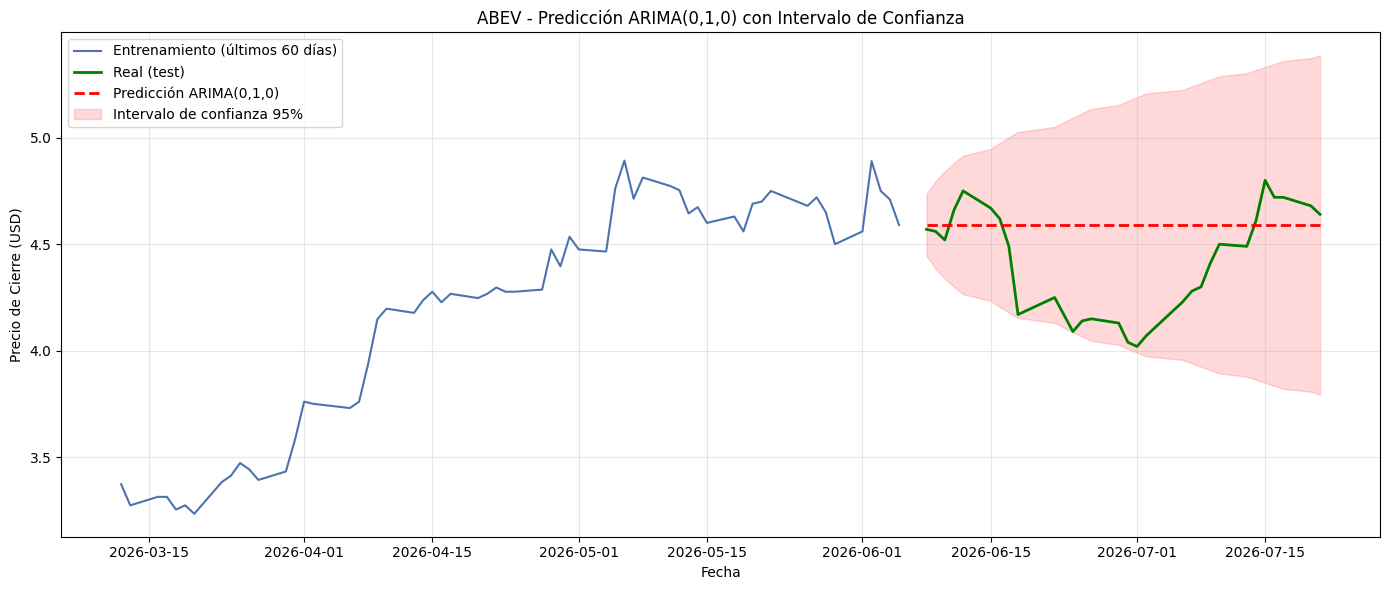

In [27]:
# Graficamos todo junto
plt.figure(figsize=(14,6))
plt.plot(train.index[-60:], train[-60:], label='Entrenamiento (últimos 60 días)', color='#4C72B0')
plt.plot(test.index, test, label='Real (test)', color='green', linewidth=2)
plt.plot(test.index, predicciones, label='Predicción ARIMA(0,1,0)', color='red', linestyle='--', linewidth=2)

# Agregamos la banda de incertidumbre
plt.fill_between(test.index, limite_inferior, limite_superior,
                  color='red', alpha=0.15, label='Intervalo de confianza 95%')

plt.title('ABEV - Predicción ARIMA(0,1,0) con Intervalo de Confianza')
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Random Forest

## Crear las features

In [28]:
# Partimos de data_reciente (2024-2026) para mantener consistencia con el Camino 2
df_ml = data_reciente.copy()
df_ml.head()

Price,Close,High,Low,Open,Volume,MA50,MA200
Ticker,GGB,GGB,GGB,GGB,GGB,,
Date,,,,,,,
2024-01-02,3.716818,3.794251,3.701331,3.755535,5903040,3.568532,3.728181
2024-01-03,3.685844,3.716818,3.670357,3.701331,4828920,3.577537,3.730036
2024-01-04,3.654870,3.685844,3.639384,3.670357,4153080,3.584707,3.731632
2024-01-05,3.678100,3.693587,3.647127,3.647127,5254080,3.592798,3.733170
2024-01-08,3.732305,3.763278,3.670357,3.701331,8017200,3.602276,3.734868


In [29]:
# --- Lags: precio de cierre de días anteriores ---
df_ml['lag_1'] = df_ml['Close'].shift(1)
df_ml['lag_2'] = df_ml['Close'].shift(2)
df_ml['lag_3'] = df_ml['Close'].shift(3)
df_ml['lag_5'] = df_ml['Close'].shift(5)

In [30]:
df_ml.head()

Price,Close,High,Low,Open,Volume,MA50,MA200,lag_1,lag_2,lag_3,lag_5
Ticker,GGB,GGB,GGB,GGB,GGB,,,,,,
Date,,,,,,,,,,,
2024-01-02,3.716818,3.794251,3.701331,3.755535,5903040,3.568532,3.728181,NaN,NaN,NaN,NaN
2024-01-03,3.685844,3.716818,3.670357,3.701331,4828920,3.577537,3.730036,3.716818,NaN,NaN,NaN
2024-01-04,3.654870,3.685844,3.639384,3.670357,4153080,3.584707,3.731632,3.685844,3.716818,NaN,NaN
2024-01-05,3.678100,3.693587,3.647127,3.647127,5254080,3.592798,3.733170,3.654870,3.685844,3.716818,NaN
2024-01-08,3.732305,3.763278,3.670357,3.701331,8017200,3.602276,3.734868,3.678100,3.654870,3.685844,NaN


In [31]:
# --- Medias móviles (ya las habíamos calculado, las recalculamos acá por si acaso) ---
df_ml['MA5'] = df_ml['Close'].rolling(window=5).mean()
df_ml['MA10'] = df_ml['Close'].rolling(window=10).mean()
df_ml['MA20'] = df_ml['Close'].rolling(window=20).mean()

In [32]:
# --- Volatilidad reciente (desviación estándar de los últimos 5 días) ---
df_ml['volatilidad_5'] = df_ml['Close'].rolling(window=5).std()

# --- Volumen ---
df_ml['volumen_lag1'] = df_ml['Volume'].shift(1)

# --- Variable objetivo (target): el precio de cierre del día siguiente ---
df_ml['target'] = df_ml['Close'].shift(-1)

# Eliminamos filas con NaN (generadas por los lags/rolling al principio, y por el shift(-1) al final)
df_ml = df_ml.dropna()

df_ml.head()

Price,Close,High,Low,Open,Volume,MA50,MA200,lag_1,lag_2,lag_3,lag_5,MA5,MA10,MA20,volatilidad_5,volumen_lag1,target
Ticker,GGB,GGB,GGB,GGB,GGB,,,,,,,,,,,,
Date,,,,,,,,,,,,,,,,,
2024-01-30,3.314163,3.337393,3.259958,3.306419,5232000,3.555888,3.719593,3.329649,3.438056,3.430313,3.314163,3.385401,3.333521,3.438056,0.058819,7269240.0,3.275445
2024-01-31,3.275445,3.352879,3.275445,3.329649,9033000,3.545596,3.716557,3.314163,3.329649,3.438056,3.414826,3.357525,3.336618,3.415988,0.072763,5232000.0,3.298676
2024-02-01,3.298676,3.329649,3.283189,3.298676,6944760,3.535313,3.713856,3.275445,3.314163,3.329649,3.430313,3.331198,3.338167,3.396629,0.063003,9033000.0,3.345136
2024-02-02,3.345136,3.360623,3.306419,3.329649,5882280,3.528809,3.711534,3.298676,3.275445,3.314163,3.438056,3.312614,3.340490,3.381143,0.027046,6944760.0,3.314163
2024-02-05,3.314163,3.329649,3.259958,3.321906,5888040,3.520911,3.709825,3.345136,3.298676,3.275445,3.329649,3.309517,3.347459,3.362946,0.025447,5882280.0,3.399339


##Separar features (X) y target (y), y dividir en train/test

In [33]:
# Definimos qué columnas van a ser features (inputs) del modelo
features = ['Close', 'Volume', 'MA50', 'MA200', 'lag_1', 'lag_2', 'lag_3',
            'lag_5', 'MA5', 'MA10', 'MA20', 'volatilidad_5', 'volumen_lag1']

X = df_ml[features]
y = df_ml['target']

# Mismo criterio que con ARIMA: los últimos 30 días para test, el resto para entrenar
n_test = 30
X_train, X_test = X[:-n_test], X[-n_test:]
y_train, y_test = y[:-n_test], y[-n_test:]

print("Filas de entrenamiento:", len(X_train))
print("Filas de test:", len(X_test))

Filas de entrenamiento: 589
Filas de test: 30


##Entrenar el modelo (Random Forest)

In [34]:
!pip install scikit-learn -q
from sklearn.ensemble import RandomForestRegressor

In [35]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Definimos la grilla de hiperparámetros a probar
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 6, 8, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# TimeSeriesSplit: 5 divisiones respetando el orden temporal
tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',  # minimizamos el MAE
    n_jobs=-1,  # usa todos los núcleos disponibles, más rápido
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Mejores parámetros:", grid_search.best_params_)
print("Mejor MAE (en CV):", -grid_search.best_score_)

Fitting 5 folds for each of 135 candidates, totalling 675 fits
Mejores parámetros: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Mejor MAE (en CV): 0.15890596448598002


In [36]:
mejor_modelo_rf = grid_search.best_estimator_

predicciones_rf = mejor_modelo_rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, predicciones_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, predicciones_rf))
mape_rf = np.mean(np.abs((y_test.values - predicciones_rf) / y_test.values)) * 100

print(f"MAE  (RF optimizado): ${mae_rf:.4f}")
print(f"RMSE (RF optimizado): ${rmse_rf:.4f}")
print(f"MAPE (RF optimizado): {mape_rf:.2f}%")

MAE  (RF optimizado): $0.1357
RMSE (RF optimizado): $0.1810
MAPE (RF optimizado): 3.19%


## verificacion

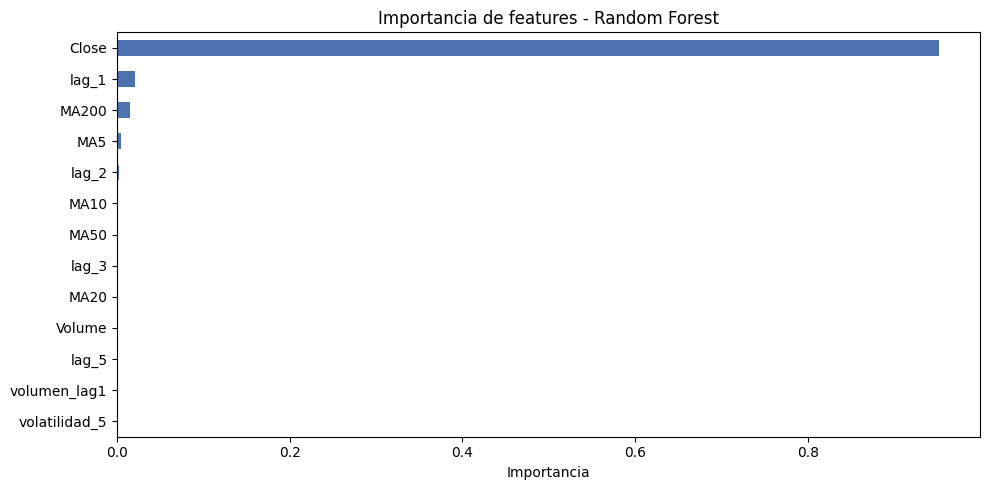

Close            0.951992
lag_1            0.020428
MA200            0.015152
MA5              0.004756
lag_2            0.001756
MA10             0.001498
MA50             0.001206
lag_3            0.000785
MA20             0.000666
Volume           0.000613
lag_5            0.000427
volumen_lag1     0.000383
volatilidad_5    0.000337
dtype: float64


In [37]:
importancias = pd.Series(mejor_modelo_rf.feature_importances_, index=features)
importancias = importancias.sort_values(ascending=False)

plt.figure(figsize=(10,5))
importancias.plot(kind='barh', color='#4C72B0')
plt.title('Importancia de features - Random Forest')
plt.xlabel('Importancia')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(importancias)

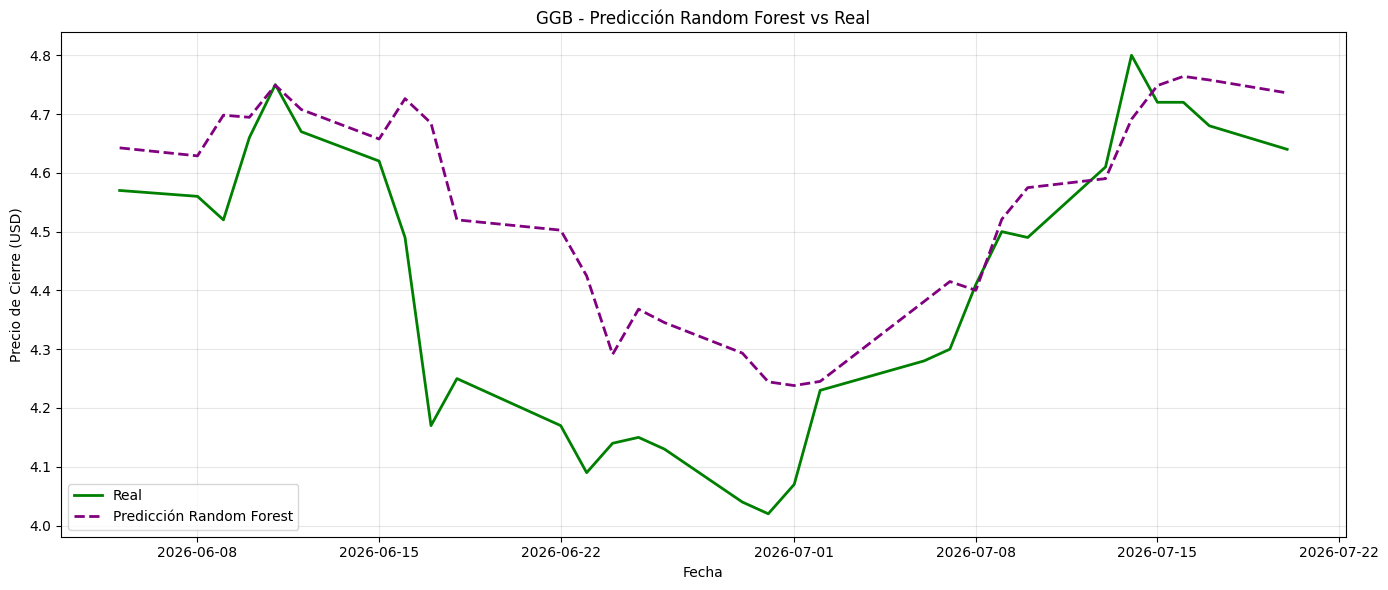

In [38]:
plt.figure(figsize=(14,6))
plt.plot(y_test.index, y_test.values, label='Real', color='green', linewidth=2)
plt.plot(y_test.index, predicciones_rf, label='Predicción Random Forest', color='purple', linestyle='--', linewidth=2)
plt.title('GGB - Predicción Random Forest vs Real')
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#Experimento sin close

In [39]:
# Features sin 'Close'
features_sin_close = ['Volume', 'MA50', 'MA200', 'lag_1', 'lag_2', 'lag_3',
                       'lag_5', 'MA5', 'MA10', 'MA20', 'volatilidad_5', 'volumen_lag1']

X_sc = df_ml[features_sin_close]
y_sc = df_ml['target']

n_test = 30
X_train_sc, X_test_sc = X_sc[:-n_test], X_sc[-n_test:]
y_train_sc, y_test_sc = y_sc[:-n_test], y_sc[-n_test:]

print("Filas de entrenamiento:", len(X_train_sc))
print("Filas de test:", len(X_test_sc))

Filas de entrenamiento: 589
Filas de test: 30


In [45]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 6, 8, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search_sc = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

grid_search_sc.fit(X_train_sc, y_train_sc)

print("Mejores parámetros:", grid_search_sc.best_params_)
print("Mejor MAE (en CV):", -grid_search_sc.best_score_)

Fitting 5 folds for each of 135 candidates, totalling 675 fits
Mejores parámetros: {'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 300}
Mejor MAE (en CV): 0.20167998615337757


In [46]:
mejor_modelo_sc = grid_search_sc.best_estimator_
predicciones_sc = mejor_modelo_sc.predict(X_test_sc)

mae_sc = mean_absolute_error(y_test_sc, predicciones_sc)
rmse_sc = np.sqrt(mean_squared_error(y_test_sc, predicciones_sc))
mape_sc = np.mean(np.abs((y_test_sc.values - predicciones_sc) / y_test_sc.values)) * 100

print(f"MAE  (RF sin Close): ${mae_sc:.4f}")
print(f"RMSE (RF sin Close): ${rmse_sc:.4f}")
print(f"MAPE (RF sin Close): {mape_sc:.2f}%")
print(f"\n--- Comparación GGB ---")
print(f"MAPE ARIMA:            5.70%")
print(f"MAPE RF (con Close):   3.15%")
print(f"MAPE RF (sin Close):   {mape_sc:.2f}%")

MAE  (RF sin Close): $0.1946
RMSE (RF sin Close): $0.2561
MAPE (RF sin Close): 4.60%

--- Comparación GGB ---
MAPE ARIMA:            5.70%
MAPE RF (con Close):   3.15%
MAPE RF (sin Close):   4.60%


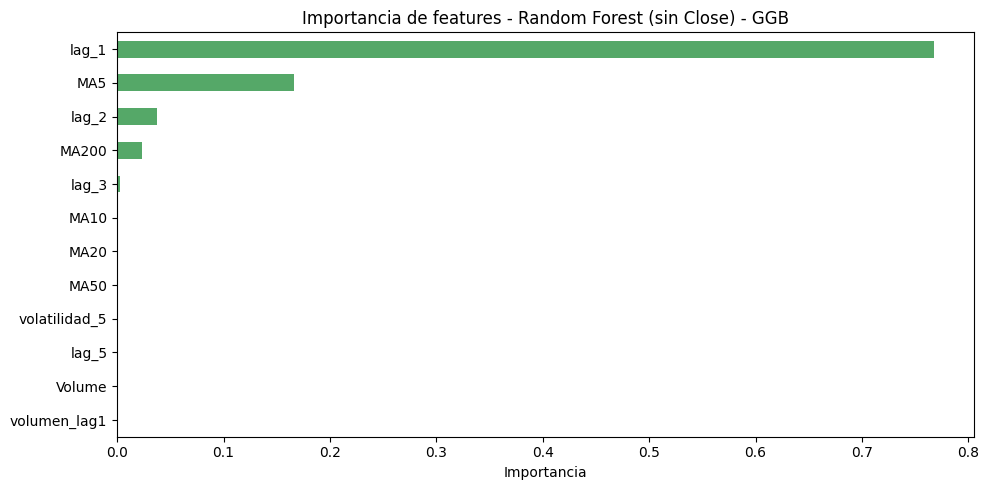

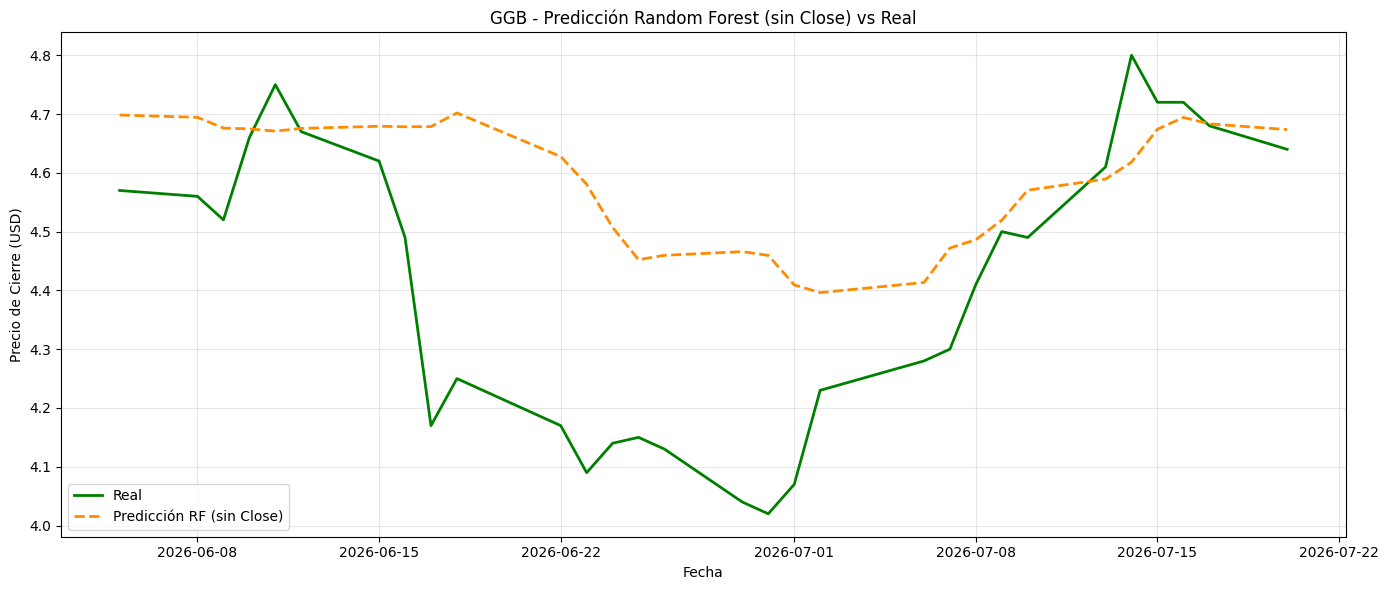

In [47]:
importancias_sc = pd.Series(mejor_modelo_sc.feature_importances_, index=features_sin_close)
importancias_sc = importancias_sc.sort_values(ascending=False)

plt.figure(figsize=(10,5))
importancias_sc.plot(kind='barh', color='#55A868')
plt.title('Importancia de features - Random Forest (sin Close) - GGB')
plt.xlabel('Importancia')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Gráfico predicción vs real
plt.figure(figsize=(14,6))
plt.plot(y_test_sc.index, y_test_sc.values, label='Real', color='green', linewidth=2)
plt.plot(y_test_sc.index, predicciones_sc, label='Predicción RF (sin Close)', color='darkorange', linestyle='--', linewidth=2)
plt.title('GGB - Predicción Random Forest (sin Close) vs Real')
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Serie completa (2020-2026)

In [40]:
modelo_auto_1 = pm.auto_arima(
    data['Close'].dropna(),
    seasonal=False,
    trace=True,           # muestra cada combinación que prueba
    suppress_warnings=True,
    stepwise=True         # búsqueda inteligente, más rápida que probar todo
)

print(modelo_auto_1.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-3570.063, Time=8.36 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-3574.639, Time=0.56 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-3572.924, Time=0.44 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-3572.947, Time=1.25 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-3576.296, Time=0.51 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-3571.819, Time=3.20 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 14.329 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1645
Model:               SARIMAX(0, 1, 0)   Log Likelihood                1789.148
Date:                Wed, 22 Jul 2026   AIC                          -3576.296
Time:                        12:28:35   BIC                          -3570.891
Sample:                             0   HQIC                         -3574.292
   

Días de entrenamiento: 1615
Días de test: 30


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/p

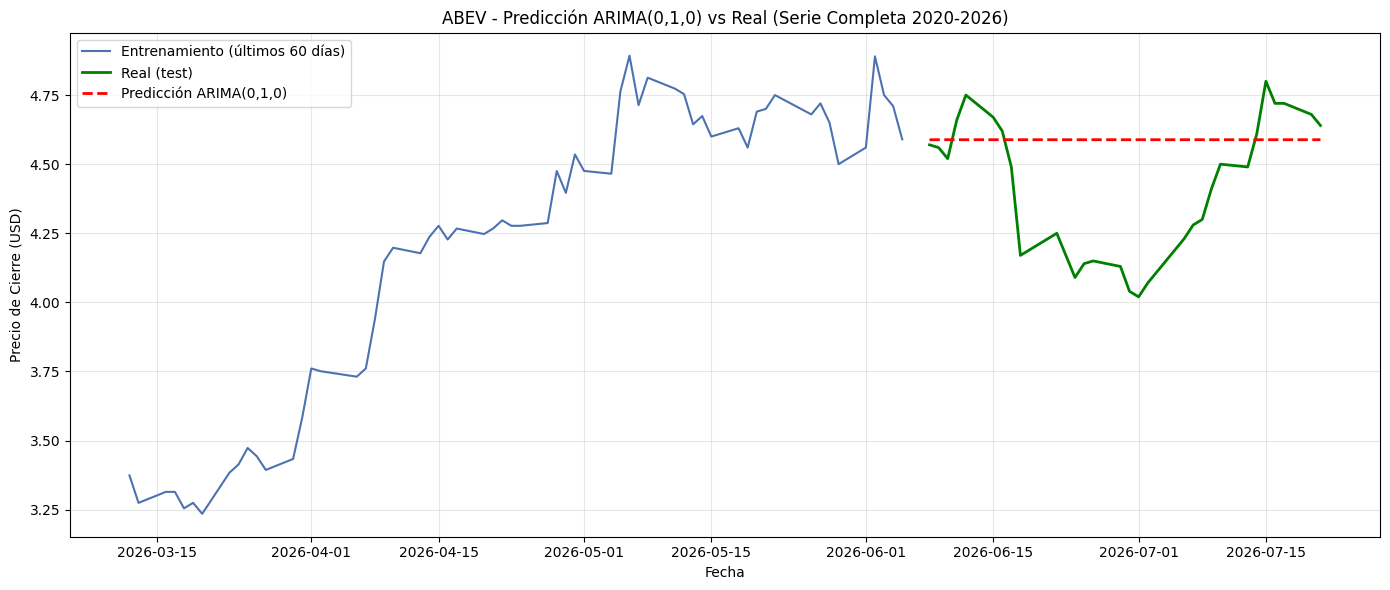

MAE  (Camino 1): $0.2392
RMSE (Camino 1): $0.3006
MAPE (corregido): 5.65%


In [41]:
# Usamos el Camino 1 (serie completa, 2020-2026)
serie_completa = data['Close'].dropna()

n_test = 30
train_c1 = serie_completa[:-n_test]
test_c1 = serie_completa[-n_test:]

print("Días de entrenamiento:", len(train_c1))
print("Días de test:", len(test_c1))

modelo_c1 = ARIMA(train_c1, order=(1,1,1))
modelo_c1_fit = modelo_c1.fit()

predicciones_c1 = modelo_c1_fit.forecast(steps=n_test)

# Graficamos
plt.figure(figsize=(14,6))
plt.plot(train_c1.index[-60:], train_c1[-60:], label='Entrenamiento (últimos 60 días)', color='#4C72B0')
plt.plot(test_c1.index, test_c1, label='Real (test)', color='green', linewidth=2)
plt.plot(test_c1.index, predicciones_c1, label='Predicción ARIMA(0,1,0)', color='red', linestyle='--', linewidth=2)

plt.title('ABEV - Predicción ARIMA(0,1,0) vs Real (Serie Completa 2020-2026)')
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Métricas
mae_c1 = mean_absolute_error(test_c1, predicciones_c1)
rmse_c1 = np.sqrt(mean_squared_error(test_c1, predicciones_c1))
mape_c1 = np.mean(np.abs((test_c1 - predicciones_c1) / test_c1)) * 100

print(f"MAE  (Camino 1): ${mae_c1:.4f}")
print(f"RMSE (Camino 1): ${rmse_c1:.4f}")
# Convertimos a arrays de numpy para evitar el problema de alineación de índices
test_vals = test_c1.values
pred_vals = predicciones_c1.values if hasattr(predicciones_c1, 'values') else np.array(predicciones_c1)

mape = np.mean(np.abs((test_vals - pred_vals) / test_vals)) * 100
print(f"MAPE (corregido): {mape:.2f}%")

Comparacion entre otros sectores

In [42]:
# Creamos el objeto Ticker (distinto a yf.download, que era solo para precios)
abev = yf.Ticker(ticker)

# Traemos la info general de la empresa
info = abev.info

# Mostramos los datos más relevantes de "categoría"
print("Nombre:", info.get('longName'))
print("Sector:", info.get('sector'))
print("Industria:", info.get('industry'))
print("País:", info.get('country'))
print("Bolsa:", info.get('exchange'))
print("Moneda:", info.get('currency'))
print("Tipo de activo:", info.get('quoteType'))

Nombre: Gerdau S.A.
Sector: Basic Materials
Industria: Steel
País: Brazil
Bolsa: NYQ
Moneda: USD
Tipo de activo: EQUITY


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


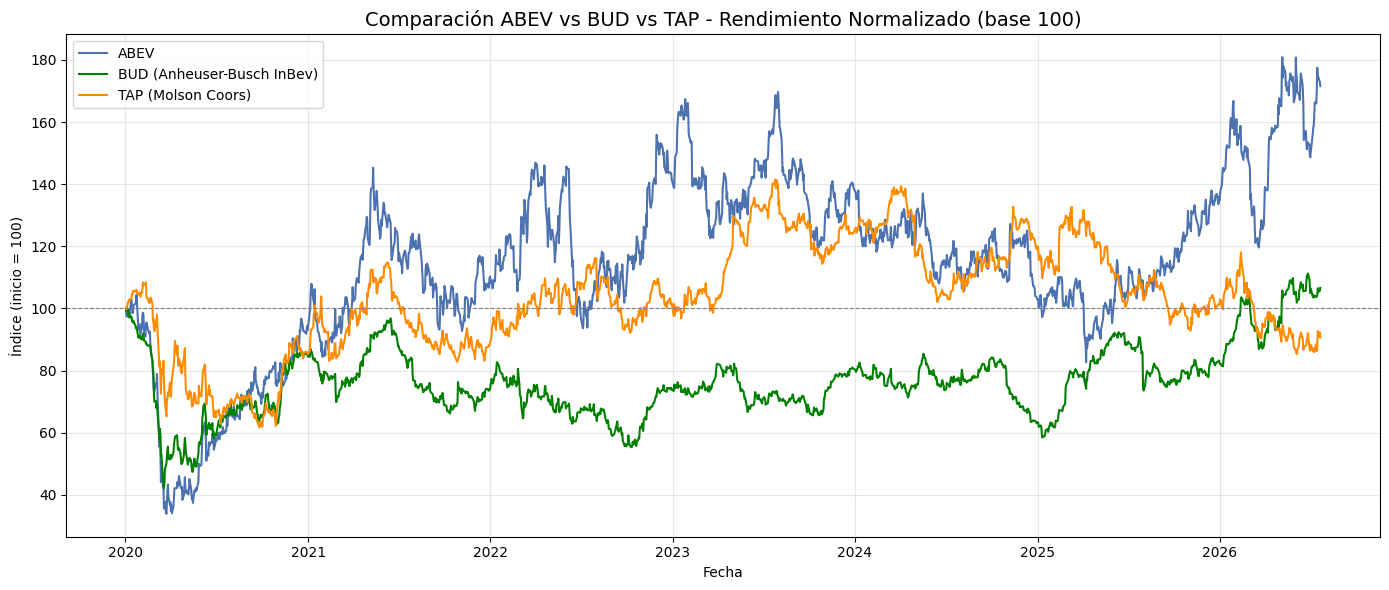

In [43]:
# Descargamos los datos de BUD para comparar
ticker2 = "BUD"
data2 = yf.download(ticker2, start="2020-01-01", end=datetime.date.today() + datetime.timedelta(days=1))
ticker3 = "TAP"
data3 = yf.download(ticker3, start="2020-01-01", end=datetime.date.today() + datetime.timedelta(days=1))


# Para comparar 2 acciones con precios distintos, lo mejor es normalizar
# (ver el % de cambio desde el inicio, no el precio absoluto)
abev_norm = data['Close'] / data['Close'].iloc[0] * 100
bud_norm = data2['Close'] / data2['Close'].iloc[0] * 100
tap_norm = data3['Close'] / data3['Close'].iloc[0] * 100

# Graficamos las 3 juntas
plt.figure(figsize=(14, 6))
plt.plot(abev_norm.index, abev_norm, label='ABEV', color='#4C72B0')
plt.plot(bud_norm.index, bud_norm, label='BUD (Anheuser-Busch InBev)', color='green')
plt.plot(tap_norm.index, tap_norm, label='TAP (Molson Coors)', color='darkorange')

plt.title('Comparación ABEV vs BUD vs TAP - Rendimiento Normalizado (base 100)', fontsize=14)
plt.xlabel('Fecha')
plt.ylabel('Índice (inicio = 100)')
plt.axhline(100, color='gray', linestyle='--', linewidth=0.8)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

[*********************100%***********************]  1 of 1 completed


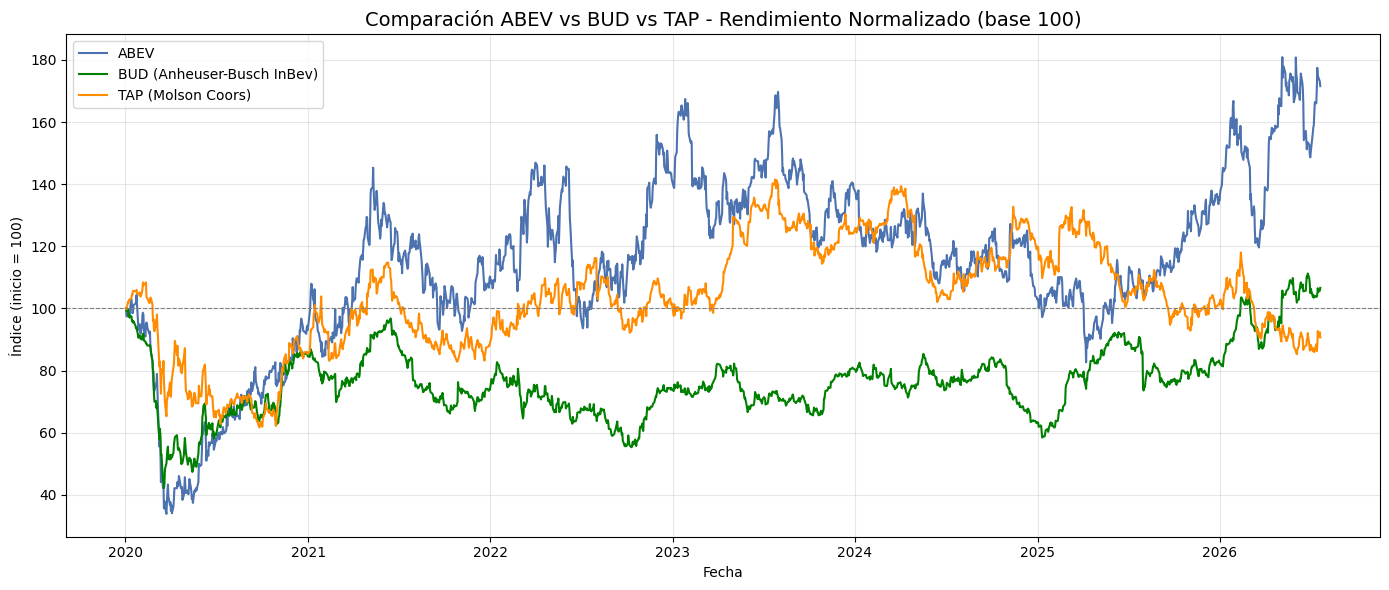

In [44]:
# Descargamos los datos de TAP
ticker3 = "TAP"
data3 = yf.download(ticker3, start="2020-01-01", end=datetime.date.today() + datetime.timedelta(days=1))

# Normalizamos igual que las anteriores (base 100)
tap_norm = data3['Close'] / data3['Close'].iloc[0] * 100

# Graficamos las 3 juntas
plt.figure(figsize=(14, 6))
plt.plot(abev_norm.index, abev_norm, label='ABEV', color='#4C72B0')
plt.plot(bud_norm.index, bud_norm, label='BUD (Anheuser-Busch InBev)', color='green')
plt.plot(tap_norm.index, tap_norm, label='TAP (Molson Coors)', color='darkorange')

plt.title('Comparación ABEV vs BUD vs TAP - Rendimiento Normalizado (base 100)', fontsize=14)
plt.xlabel('Fecha')
plt.ylabel('Índice (inicio = 100)')
plt.axhline(100, color='gray', linestyle='--', linewidth=0.8)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()